<a href="https://colab.research.google.com/github/dhatrisrivadupu/ML-projects/blob/main/ML5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures

In [ ]:
dataset=pd.read_csv('/content/ML.csv')

In [ ]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       1000 non-null   float64
 1   y       1000 non-null   float64
dtypes: float64(2)
memory usage: 15.8 KB


In [ ]:
dataset.describe()

,x,y
count,1000.000000,1000.000000
mean,-0.027201,73.613661
std,5.850491,63.767035
min,-9.988547,-9.299270
25%,-5.061974,18.132173
50%,-0.135796,54.387525
75%,4.987739,122.281817
max,9.991836,237.950299


In [ ]:
dataset.isnull().sum()

,0
x,0
y,0


In [ ]:
dataset.head()

,x,y
0,1.409445,5.275026
1,-9.337377,212.625146
2,-6.951291,124.721516
3,3.781497,20.279580
4,-5.841269,93.034061


In [ ]:
dataset.shape

(1000, 2)

In [ ]:
# Check duplicate records
print(dataset.duplicated().sum())
# Remove duplicates if any
dataset.drop_duplicates(inplace=True)

0


<Axes: ylabel='x'>

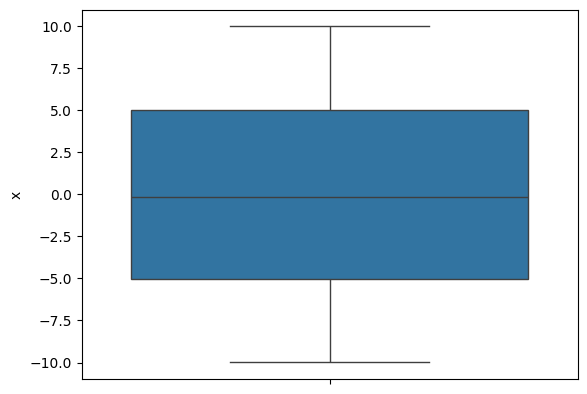

In [ ]:
#Outlier detection
sns.boxplot(dataset['x'])

In [ ]:
#independent variable
x=dataset['x']

In [ ]:
#dependent variable
y=dataset['y']

Text(0, 0.5, 'y')

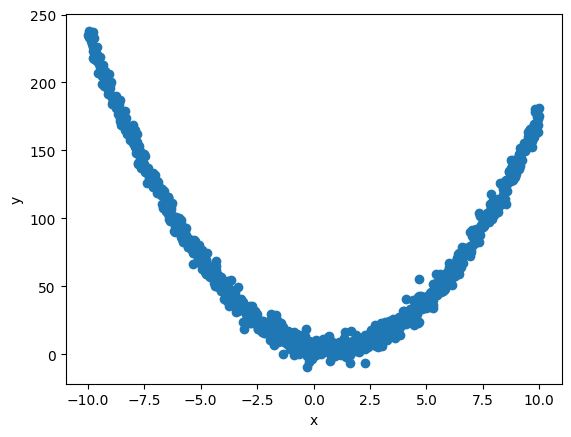

In [ ]:
plt.scatter(x, y)
plt.xlabel('x')
plt.ylabel('y')

In [ ]:
# Check duplicate records
print(dataset.duplicated().sum())
# Remove duplicates if any
dataset.drop_duplicates(inplace=True)

0


In [ ]:
# Split the dataset into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.15, random_state=123)

In [ ]:
print('First 5 rows of x_train:')
display(x_train.head())
print('\nFirst 5 rows of y_train:')
display(y_train.head())

First 5 rows of x_train:


,x
923,4.903405
188,-0.222272
669,-5.550368
688,-6.294938
375,-8.527878



First 5 rows of y_train:


,y
923,39.209560
188,2.352360
669,84.974798
688,111.449504
375,168.409262


In [ ]:
print('First 5 rows of x_test:')
display(x_test.head())
print('\nFirst 5 rows of y_test:')
display(y_test.head())

First 5 rows of x_test:


,x
131,-5.452191
203,-8.535653
50,-9.004854
585,2.090895
138,-3.262837



First 5 rows of y_test:


,y
131,83.735988
203,178.800180
50,191.430795
585,10.423690
138,35.655233


In [ ]:
print(f"Number of instances for training: {len(x_train)}")
print(f"Number of instances for testing: {len(x_test)}")

Number of instances for training: 850
Number of instances for testing: 150


In [ ]:
poly_features=PolynomialFeatures(degree=2)

In [ ]:
x_poly=poly_features.fit_transform(x.to_frame())

In [ ]:
lr_model=LinearRegression()
lr_model.fit(x_poly,y)

LinearRegression()

In [ ]:
model = LinearRegression()
x_train_poly = poly_features.transform(x_train.to_frame())
model.fit(x_train_poly, y_train)
print("Model Trained Successfully")

Model Trained Successfully


In [ ]:
y_pred=lr_model.predict(x_poly)
df=pd.DataFrame({'Actual':y,'Predicted':y_pred})
print(df)

         Actual   Predicted
0      5.275026    4.903998
1    212.625146  207.614460
2    124.721516  122.733345
3     20.279580   22.359846
4     93.034061   91.002767
..          ...         ...
995  117.422861  120.163606
996  111.887072  111.092371
997   59.801025   61.241090
998    4.401643    5.153428
999   58.191178   54.258772

[1000 rows x 2 columns]


In [ ]:
# Evaluate model performance on training data using MAE, MSE, RMSE, and R2 score
y_train_pred = model.predict(x_train_poly)
mae = mean_absolute_error(y_train, y_train_pred)
mse = mean_squared_error(y_train, y_train_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_train, y_train_pred)
print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root MSE (RMSE):", rmse)
print("R2 Score:", r2)

Mean Absolute Error (MAE): 3.8289311697624826
Mean Squared Error (MSE): 22.95208049674198
Root MSE (RMSE): 4.79083296481332
R2 Score: 0.9943530771711432


In [ ]:
# Evaluate model performance on testing data using MAE, MSE, RMSE, and R2 score
x_test_poly = poly_features.transform(x_test.to_frame())
y_test_pred = model.predict(x_test_poly)
mae = mean_absolute_error(y_test, y_test_pred)
mse = mean_squared_error(y_test, y_test_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_test_pred)
print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root MSE (RMSE):", rmse)
print("R2 Score: ", r2)

Mean Absolute Error (MAE): 3.7387118108241717
Mean Squared Error (MSE): 22.68567596347127
Root MSE (RMSE): 4.762948242787367
R2 Score:  0.9943912882899916


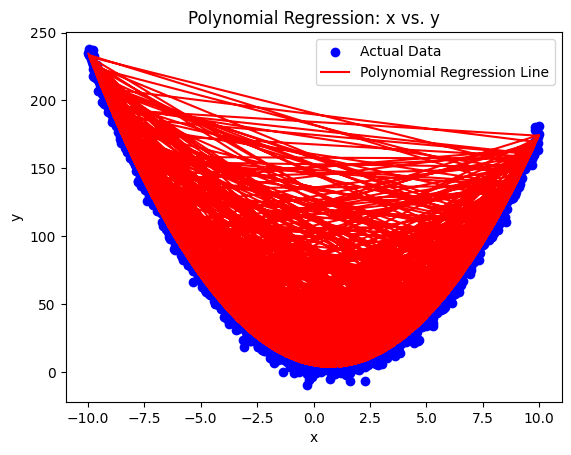

In [ ]:
plt.scatter(x, y, color='blue', label='Actual Data')
plt.plot(x, model.predict(poly_features.transform(x.to_frame())), color='red', label='Polynomial Regression Line')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Polynomial Regression: x vs. y')
plt.legend()
plt.show()